# Possession and pass-event detection

**Analytical question:** Recover candidate on-ball events.

**Stages in this notebook:** Player–ball vectors; proximity; stable possession; release/transit/reception; timing evaluation.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


**Reading order:** follow the numbered stages. Each helper is introduced before its first use, then its intermediate output is inspected. The final result comes after those stages.

## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## 2. Inline ingestion and plotting helpers

In [2]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [3]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## 4. Calculate player–ball vectors

Inspect coordinate differences for one frame before calculating possession candidates.

,player,dx,dy,distance_m
6174,966112,2.08,1.55,2.594012
98469,287934,4.36,1.15,4.509113
36939,51002,-5.44,-2.23,5.879328
21,51050,7.62,-3.19,8.260781
30786,560986,-3.24,-8.02,8.649740
55398,560984,-3.09,-8.20,8.762882
43092,560882,-8.46,5.84,10.279942
116928,965697,10.33,4.86,11.416151


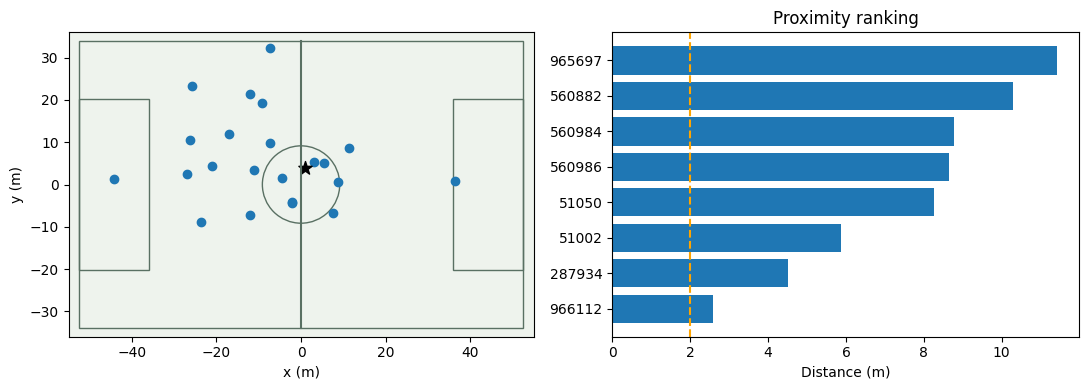

In [4]:
def player_ball_vectors(players,ball_xy):
    return players[['x','y']].to_numpy()-np.asarray(ball_xy)

def vector_lengths(vectors):
    return np.sqrt((vectors**2).sum(axis=1))
ball_row=wide[wide.frame_id.eq(frame_id)].iloc[0];ball_xy=np.array([ball_row.ball_x,ball_row.ball_y])
players=snapshot.copy();vectors=player_ball_vectors(players,ball_xy);players['distance_m']=vector_lengths(vectors)
display(pd.DataFrame({'player':players.player_id,'dx':vectors[:,0],'dy':vectors[:,1],'distance_m':players.distance_m}).sort_values('distance_m').head(8))
fig,axs=plt.subplots(1,2,figsize=(11,4));pitch(axs[0]);axs[0].scatter(players.x,players.y);axs[0].scatter(*ball_xy,marker='*',c='black',s=100)
rank=players.nsmallest(8,'distance_m');axs[1].barh(rank.player_id,rank.distance_m);axs[1].axvline(2,c='orange',ls='--');axs[1].set(xlabel='Distance (m)',title='Proximity ranking');plt.tight_layout();plt.show()

## 5. Create nearest-player candidates over time

Apply the distance calculation to all frames. The radius and height cutoff are explicit teaching choices.

,frame_id,player_id,distance,ball_z,candidate
24603,40,51002,0.909340,0.30,51002
24604,41,51002,1.387083,0.28,51002
24605,42,51002,2.025562,0.26,NaN
24606,43,51002,2.745269,0.24,NaN
24607,44,51002,3.503655,0.22,NaN
24608,45,51002,4.243018,0.22,NaN
24609,46,51002,4.922286,0.21,NaN
24610,47,51002,5.563596,0.19,NaN
24611,48,51002,6.237219,0.18,NaN
6162,49,287934,6.288283,0.16,NaN


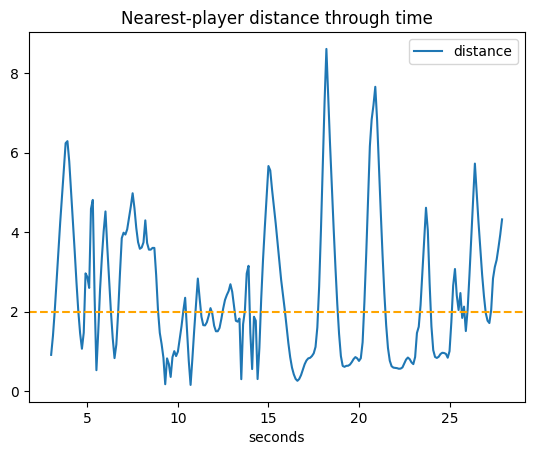

In [5]:
joined=observed.merge(wide[['period_id','frame_id','ball_x','ball_y','ball_z']],on=['period_id','frame_id'],validate='many_to_one')
joined['distance']=np.hypot(joined.x-joined.ball_x,joined.y-joined.ball_y)
valid=joined.dropna(subset=['distance']);nearest=valid.loc[valid.groupby(['period_id','frame_id']).distance.idxmin()].sort_values(['period_id','frame_id']).copy()
nearest['candidate']=nearest.player_id.where(nearest.distance.le(2)&nearest.ball_z.le(2))
display(nearest[['frame_id','player_id','distance','ball_z','candidate']].head(12))
nearest.head(250).plot(x='seconds',y='distance',title='Nearest-player distance through time');plt.axhline(2,c='orange',ls='--');plt.show()

## 6. Group stable possession intervals

Only after seeing frame candidates do we merge consecutive identical labels. Gaps and period changes start new segments.

In [6]:
nearest['break']=nearest.period_id.ne(nearest.period_id.shift())|nearest.frame_id.diff().ne(1)|nearest.candidate.ne(nearest.candidate.shift())
nearest['segment']=nearest['break'].cumsum()
segments=nearest.groupby('segment').agg(period=('period_id','first'),start=('frame_id','min'),end=('frame_id','max'),player=('candidate','first'),team=('team_id','first'),frames=('frame_id','size'))
segments['duration_s']=segments.frames/10
stable=segments[segments.player.notna()&segments.duration_s.ge(.3)].copy()
display(stable.head(12))

,period,start,end,player,team,frames,duration_s
segment,,,,,,,
16,1,56,58,51050,1802,3,0.3
58,1,100,104,797298,1802,5,0.5
59,1,105,109,966114,871,5,0.5
73,1,123,127,560989,871,5,0.5
75,1,129,132,560882,1802,4,0.4
110,1,170,187,965697,1802,18,1.8
122,1,199,212,51050,1802,14,1.4
135,1,225,242,560983,1802,18,1.8
143,1,250,261,560986,1802,12,1.2


## 7. Inspect ball travel before identifying passes

Introduce the ball-path helper and inspect displacement and speed on a continuous sample. This is the evidence used in the next step.

,frame_id,dt,step_m,ball_speed_mps
0,40,NaN,NaN,NaN
1,41,0.1,0.460109,4.601087
2,42,0.1,0.600083,6.000833
3,43,0.1,0.660076,6.600758
4,44,0.1,0.680074,6.800735
5,45,0.1,0.650077,6.500769
6,46,0.1,0.560357,5.603570
7,47,0.1,0.511566,5.115662
8,48,0.1,0.516236,5.162364
9,49,0.1,0.482597,4.825971


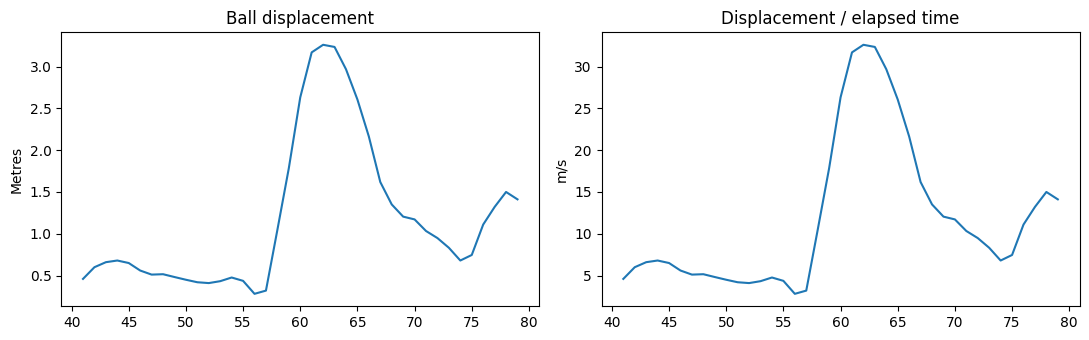

In [7]:
def ball_path_steps(path):
    path=path.sort_values('frame_id').copy()
    path['dt']=path.timestamp.dt.total_seconds().diff()
    path['step_m']=np.hypot(path.ball_x.diff(),path.ball_y.diff())
    valid=path.frame_id.diff().eq(1)&path.dt.gt(0)
    path['ball_speed_mps']=(path.step_m/path.dt).where(valid)
    return path
path=ball_path_steps(wide.head(40))
display(path[['frame_id','dt','step_m','ball_speed_mps']].head(10))
fig,axs=plt.subplots(1,2,figsize=(11,3.5));axs[0].plot(path.frame_id,path.step_m);axs[0].set(title='Ball displacement',ylabel='Metres');axs[1].plot(path.frame_id,path.ball_speed_mps);axs[1].set(title='Displacement / elapsed time',ylabel='m/s');plt.tight_layout();plt.show()

## 8. Final detection output: pass candidates

Pair stable same-team possessions only when the intervening ball path is covered and moves at least three metres.

,period,release,reception,passer,receiver,displacement_m
0,1,109,123,966114,560989,10.225380
1,1,132,170,560882,965697,27.147361
2,1,187,199,965697,51050,17.012010
3,1,212,225,51050,560983,16.841954
4,1,242,250,560983,560986,8.693590
5,1,343,358,11897,966114,14.703496
6,1,368,376,966114,795530,5.110773
7,1,385,398,795530,560984,16.305760
8,1,569,574,287934,51050,4.323806
9,1,1262,1281,51002,560986,7.681881


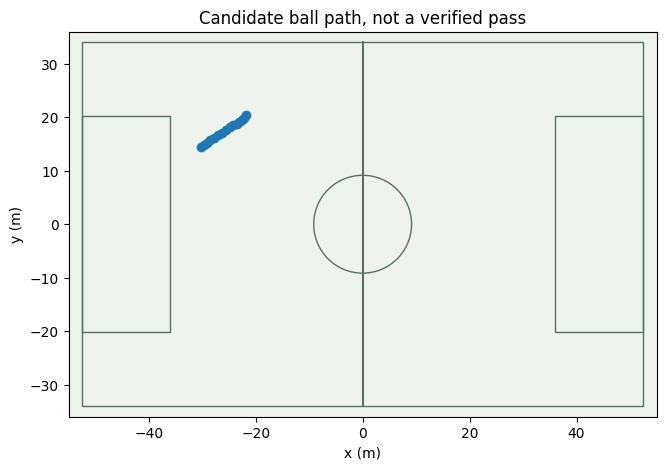

In [8]:
def detect_pass_candidates(stable,wide):
    result=[]
    for a,b in zip(stable.itertuples(),list(stable.itertuples())[1:]):
        if a.period!=b.period or a.player==b.player or a.team!=b.team:continue
        gap=b.start-a.end
        path=ball_path_steps(wide[wide.period_id.eq(a.period)&wide.frame_id.between(a.end,b.start)])
        if not 1<=gap<=40 or len(path)!=gap+1 or path[['ball_x','ball_y']].isna().any().any():continue
        displacement=np.linalg.norm(path[['ball_x','ball_y']].iloc[-1]-path[['ball_x','ball_y']].iloc[0])
        if displacement>=3:result.append(dict(period=a.period,release=a.end,reception=b.start,passer=a.player,receiver=b.player,displacement_m=displacement))
    return pd.DataFrame(result,columns=['period','release','reception','passer','receiver','displacement_m'])
passes=detect_pass_candidates(stable,wide);display(passes.head(10))
fig,ax=plt.subplots(figsize=(9,5));pitch(ax)
if len(passes):
    p=passes.iloc[0];path=wide[wide.period_id.eq(p.period)&wide.frame_id.between(p.release,p.reception)];ax.plot(path.ball_x,path.ball_y,'o-')
ax.set_title('Candidate ball path, not a verified pass');plt.show()

### Video: inspect a candidate pass

Follow the nearest-player distance, the 2 m proximity gate and the release/transit/reception candidate. The clip uses stable control of at least 0.3 s and a ball-height gate of 2 m; playback is half speed. It is an unverified heuristic candidate, not a provider-labeled pass or a measured detector result.

The MP4 is embedded in the saved notebook and HTML export. Playback needs no live kernel; rerun the cell to reload the local asset or fetch its pinned public copy.

In [ ]:
# MP4 playback is optional; all method calculations above remain inline.
from pathlib import Path
import hashlib
import urllib.request
from IPython.display import Video, display

video_name = "event_detection.mp4"
video_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                   if (p / "assets" / "videos" / video_name).is_file()), None)
if video_root is not None:
    video_bytes = (video_root / "assets" / "videos" / video_name).read_bytes()
else:
    # A downloaded notebook can retrieve the same public, pinned slide asset.
    video_cache = Path.cwd() / "data" / "workshop_videos"
    video_cache.mkdir(parents=True, exist_ok=True)
    video_file = video_cache / video_name
    if not video_file.exists():
        video_url = ("https://raw.githubusercontent.com/zcochran27/"
                     "tracking-data-applied-workshop/3ddf4e6/assets/videos/" + video_name)
        with urllib.request.urlopen(video_url, timeout=90) as response:
            video_file.write_bytes(response.read())
    video_bytes = video_file.read_bytes()
assert hashlib.sha256(video_bytes).hexdigest() == "45569d91b0c0c336cd81d1f509188abbd9b76150712db2c82ec6e93d7ed8c7c2", "Video checksum mismatch"
display(Video(data=video_bytes, embed=True, mimetype="video/mp4", width=960,
              html_attributes='controls preload="metadata" style="max-width:100%;height:auto"'))


## 9. Evaluate timing with one-to-one matching

Evaluation follows detection. This synthetic check illustrates tolerance sensitivity; it is not a measured accuracy result.

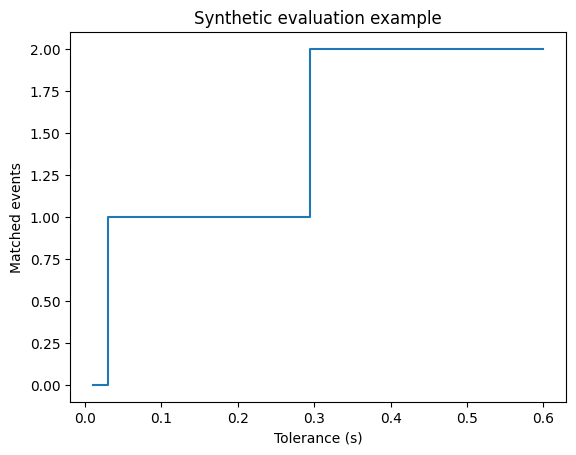

In [9]:
from scipy.optimize import linear_sum_assignment
def timing_scores(predicted,truth,tolerance_s=.5):
    predicted=np.asarray(predicted);truth=np.asarray(truth)
    if not len(predicted) or not len(truth):return {'tp':0,'fp':len(predicted),'fn':len(truth)}
    delta=np.abs(predicted[:,None]-truth[None,:])
    # A large penalty first maximizes the count of eligible one-to-one matches.
    cost=np.where(delta<=tolerance_s,delta,1e6)
    rows,cols=linear_sum_assignment(cost);tp=int((delta[rows,cols]<=tolerance_s).sum())
    return {'tp':tp,'fp':len(predicted)-tp,'fn':len(truth)-tp}
assert timing_scores([1,1.1],[1],.2)=={'tp':1,'fp':1,'fn':0}
tolerances=np.linspace(.01,.6,30);counts=[timing_scores([1.,1.1,3.3],[1.05,3.,5.],t)['tp'] for t in tolerances]
plt.step(tolerances,counts);plt.xlabel('Tolerance (s)');plt.ylabel('Matched events');plt.title('Synthetic evaluation example');plt.show()

## Interpretation and limitations

Duels, flyovers, deflections and tracking gaps can fool proximity rules. Missing ball height is left unassigned. Validate against video-reviewed events. This does not reproduce [PathCRF](https://github.com/hyunsungkim-ds/pathcrf).